# NLP Sentiment Classification on Customer Reviews (TF-IDF)

**Objective:** clean df review text, convert it to TF-IDF features, and classify sentiment polarity with Multinomial Naive Bayes and Logistic Regression, then wrap the best model in a `predict_sentiment()` helper for live input.

**Pipeline:** df text -> clean (lowercase, strip HTML/punctuation, stopwords, lemmatize) -> TF-IDF (5,000 features) -> classifier -> evaluation -> live prediction.

In [14]:
import re, warnings
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from functools import lru_cache
warnings.filterwarnings("ignore", category=FutureWarning)

from nltk.corpus import stopwords, movie_reviews
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

for pkg in ["stopwords", "wordnet", "movie_reviews"]:
    nltk.download(pkg, quiet=True)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [15]:
url = "https://www.datheon.in/datasets/sentiment_reviews.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

print("\nDataset shape:", df.shape)

print("\nFirst five rows:", df.head())

Dataset loaded successfully!

Dataset shape: (10, 3)

First five rows:    review_id                                        review_text sentiment
0          1  The product quality is exceptional, exceeded a...  positive
1          2  Terrible customer service and the item arrived...  negative
2          3  Average performance, decent for the price poin...   neutral
3          4  Absolutely love this! Easy to setup, robust, a...  positive
4          5  Stopped working after two days. Extremely disa...  negative


In [16]:
print("Column names:", df.columns.tolist())

print("\nMissing Values:" , df.isnull().sum())

print("\nDuplicate Rows:" , df.duplicated().sum())

print("\nNumerical Summary:" , display( df.describe()))

print("\nSentiment distribution:" , df["sentiment"].value_counts())

print("\nDataset information:", df.info())


Column names: ['review_id', 'review_text', 'sentiment']

Missing Values: review_id      0
review_text    0
sentiment      0
dtype: int64

Duplicate Rows: 0


,review_id
count,10.00000
mean,5.50000
std,3.02765
min,1.00000
25%,3.25000
50%,5.50000
75%,7.75000
max,10.00000



Numerical Summary: None

Sentiment distribution: sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    10 non-null     int64 
 1   review_text  10 non-null     object
 2   sentiment    10 non-null     object
dtypes: int64(1), object(2)
memory usage: 372.0+ bytes

Dataset information: None


In [22]:
MIN_ROWS = 500   # below this, a train/test split is too small to benchmark anything

if len(df) >= MIN_ROWS:
    data = df.rename(columns={"review_text": "text"})[["text", "sentiment"]].copy()
    data = data[data["sentiment"].isin(["positive", "negative"])]      # task is binary polarity
    corpus_name = "Datheon sentiment_reviews.csv"
else:
    print(f"Provided file has only {len(df)} rows -> using NLTK movie_reviews (2,000 labelled reviews) as the benchmark corpus.")
    fileids = movie_reviews.fileids()
    data = pd.DataFrame({
        "text": [movie_reviews.raw(fid) for fid in fileids],
        "sentiment": [movie_reviews.categories(fid)[0].replace("pos", "positive").replace("neg", "negative")
                      for fid in fileids],
    })
    corpus_name = "NLTK movie_reviews"

data = data.dropna().drop_duplicates().reset_index(drop=True)
print("\nCorpus:", corpus_name, "| rows:", len(data))
print("\nSentiment distribution:")
print(data["sentiment"].value_counts())

display(data.head())

Provided file has only 10 rows -> using NLTK movie_reviews (2,000 labelled reviews) as the benchmark corpus.

Corpus: NLTK movie_reviews | rows: 2000

Sentiment distribution:
sentiment
negative    1000
positive    1000
Name: count, dtype: int64


,text,sentiment
0,"plot : two teen couples go to a church party ,...",negative
1,the happy bastard's quick movie review \ndamn ...,negative
2,it is movies like these that make a jaded movi...,negative
3,""" quest for camelot "" is warner bros . ' firs...",negative
4,synopsis : a mentally unstable man undergoing ...,negative


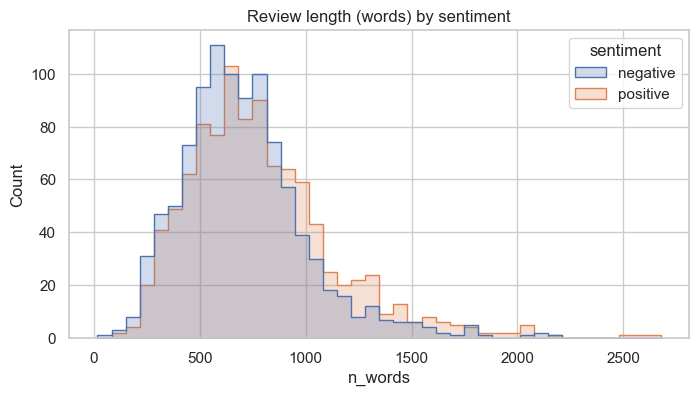

            count   mean    std    min    25%    50%    75%     max
sentiment                                                          
negative   1000.0  705.6  296.7   17.0  510.0  668.5  848.2  2181.0
positive   1000.0  787.1  352.8  130.0  543.5  731.5  957.2  2678.0


In [23]:
data["n_words"] = data["text"].str.split().str.len()
plt.figure(figsize=(8, 4))
sns.histplot(data=data, x="n_words", hue="sentiment", bins=40, element="step")
plt.title("Review length (words) by sentiment")
plt.show()
print(data.groupby("sentiment")["n_words"].describe().round(1))

In [24]:
# Standard stopword lists contain negations. Removing them turns "not worth the money" into "worth money".
NEGATIONS = {"no", "nor", "not", "never"}
STOP_WORDS = set(stopwords.words("english")) - NEGATIONS
lemmatizer = WordNetLemmatizer()

@lru_cache(maxsize=None)
def lemmatize(word):
    return lemmatizer.lemmatize(lemmatizer.lemmatize(word), pos="v")   # noun pass, then verb pass

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)            # strip HTML tags
    text = re.sub(r"n't\b", " not", text)           # don't -> do not (keeps the negation)
    text = re.sub(r"[^a-z\s]", " ", text)           # drop punctuation, digits, symbols
    tokens = [t for t in text.split() if len(t) > 1 and t not in STOP_WORDS]
    return " ".join(lemmatize(t) for t in tokens)

demo = "<br>I DON'T love this. It's NOT worth the money, and the delivered items were damaged!"
print("Before:", demo)
print("After :", clean_text(demo))

Before: <br>I DON'T love this. It's NOT worth the money, and the delivered items were damaged!
After : not love not worth money deliver item damage


In [25]:
data["clean_text"] = data["text"].apply(clean_text)
display(data[["text", "clean_text"]].head(3))

,text,clean_text
0,"plot : two teen couples go to a church party ,...",plot two teen couple go church party drink dri...
1,the happy bastard's quick movie review \ndamn ...,happy bastard quick movie review damn bug get ...
2,it is movies like these that make a jaded movi...,movie like make jade movie viewer thankful inv...


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    data["clean_text"], data["sentiment"],
    test_size=0.2, random_state=RANDOM_STATE, stratify=data["sentiment"]
)
print("Train:", len(X_train), "| Test:", len(X_test))
print(y_test.value_counts())

Train: 1600 | Test: 400
sentiment
negative    200
positive    200
Name: count, dtype: int64


In [27]:
def make_pipeline(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)),
        ("clf", clf),
    ])

models = {
    "Multinomial NB": make_pipeline(MultinomialNB()),
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
}
for name, model in models.items():
    model.fit(X_train, y_train)
print("Trained:", list(models))

Trained: ['Multinomial NB', 'Logistic Regression']
